-------
## Projekt 1 - Wstęp do Uczenia Maszynowego 2026Z

## Kod KM1

-------


**Imię i Nazwisko:** Krzysztof Dąbrowski

**Prowadzący:** AK

**Kierunek:** IAD

**Numer albumu:** 338980

------

### *Import pakietów*

-------

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, validation_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.feature_selection import mutual_info_classif

### *1. Eksploracyjna analiza danych*
-------

In [3]:
X_train = pd.read_csv("data/X_train.csv")
y_train = pd.read_csv("data/y_train.csv")
X_test = pd.read_csv("data/X_test.csv")

print(X_train.shape, y_train.shape)
y_train.head()

(6400, 23) (6400, 1)


,default.payment.next.month
0,1
1,0
2,0
3,0
4,0


In [4]:
df = X_train.copy()
df["target"] = y_train["default.payment.next.month"]

df.head(10)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
0,19912.825563,2,2,1,44,2,0,0,2,2.0,...,17974.686955,18841.431580,15783.245882,1423.110120,3049.157007,157.071859,733.154414,478.947062,379.984156,1
1,55043.974658,1,1,2,24,4,4,4,4,3.0,...,38224.238356,39238.101886,40576.008942,2037.243581,1854.121994,300.752767,1020.891555,-455.518882,2469.448131,0
2,20006.277688,2,2,2,31,0,0,0,0,NaN,...,28966.654890,19049.390827,15402.347969,10175.669342,4573.613449,-771.581797,-283.002435,4857.385369,3474.203409,0
3,128698.125632,1,1,2,31,-1,-1,-1,-2,-2.0,...,-2834.834778,-786.605171,49261.032919,10858.685707,1101.369070,25.587625,-331.783255,49191.348594,3767.305856,0
4,358711.329669,2,1,1,34,-2,-2,-2,-2,-2.0,...,16441.809554,14173.086443,21134.235164,6945.506312,691.104497,7333.776096,5973.950428,5218.051932,28455.969902,0
5,51516.495849,2,3,1,50,0,0,0,0,0.0,...,29178.458784,28369.419046,30036.056620,3594.813784,10431.452282,4614.307110,640.070040,2343.333577,2376.431586,1
6,377119.773509,2,2,2,31,1,2,0,0,NaN,...,1662.343196,8026.769850,-2422.725842,3081.077082,2082.600036,6677.524125,8931.475781,1049.959505,2775.054515,0
7,31339.135516,2,2,2,25,2,2,2,0,0.0,...,25079.618196,27355.250355,25350.982824,1309.803696,-237.833975,1342.765124,1290.533511,1514.087279,1233.172406,0
8,19475.179575,2,3,2,48,0,0,0,0,0.0,...,19981.128320,21382.794994,22886.212139,535.562507,727.129536,1827.990490,533.357615,536.945737,395.177946,0
9,326670.599325,1,2,2,23,0,0,0,0,0.0,...,111700.179973,117707.579831,97876.402797,5555.250946,8193.426069,6309.375777,3608.299565,1933.434581,5678.351648,0


In [5]:
df.dtypes

LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5        float64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
target         int64
dtype: object

Zbiór treningowy ma 6400 obserwacji i 23 cechy numeryczne. Część z nich to tak naprawdę zmienne kategoryczne zapisane liczbami: `SEX`, `EDUCATION`, `MARRIAGE` i porządkowe: `PAY_*`.

### *1.1 Statystyki opisowe i rozkłady zmiennych*
-------

target
0    5019
1    1381
Name: count, dtype: int64
target
0    0.78
1    0.22
Name: proportion, dtype: float64


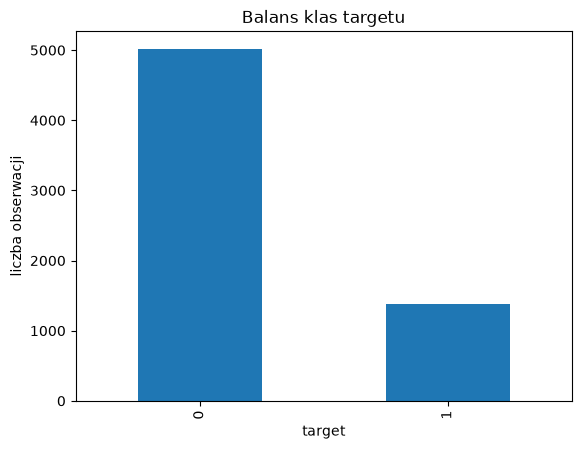

In [6]:
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True).round(2))
df["target"].value_counts().plot(kind="bar", title="Balans klas targetu")
plt.xlabel("target")
plt.ylabel("liczba obserwacji")
plt.show()

Klasy w targecie są niezbalansowane,około 78% obserwacji jest klasy 0 i 22% klasy 1.

In [7]:
desc = df.describe().T
desc["mode"] = df.mode().iloc[0]
desc

,count,mean,std,min,25%,50%,75%,max,mode
LIMIT_BAL,6400.0,167058.277002,130788.623708,-157.510827,54027.835110,138508.702518,236847.697924,783258.369189,-157.510827
SEX,6400.0,1.600781,0.489776,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000
EDUCATION,6400.0,1.837344,0.796703,0.000000,1.000000,2.000000,2.000000,6.000000,2.000000
MARRIAGE,6400.0,1.565313,0.518858,0.000000,1.000000,2.000000,2.000000,3.000000,2.000000
AGE,6400.0,34.828437,9.090674,19.000000,28.000000,33.000000,41.000000,73.000000,29.000000
PAY_0,6400.0,-0.016875,1.132852,-2.000000,-1.000000,0.000000,0.000000,8.000000,0.000000
PAY_2,6400.0,-0.147813,1.179351,-2.000000,-1.000000,0.000000,0.000000,7.000000,0.000000
PAY_3,6400.0,-0.165469,1.189615,-3.000000,-1.000000,0.000000,0.000000,7.000000,0.000000
PAY_4,6400.0,-0.229687,1.158643,-2.000000,-1.000000,0.000000,0.000000,7.000000,0.000000
PAY_5,5764.0,-0.277412,1.122036,-2.000000,-1.000000,0.000000,0.000000,7.000000,0.000000


Cechy kwoty `LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*`, mają średnią wyraźnie większą od mediany, co wskazuje na ich prawoskośność. Minimalne wartości kwot są ujemne, co jest dziwne i wrócę do tego potem.

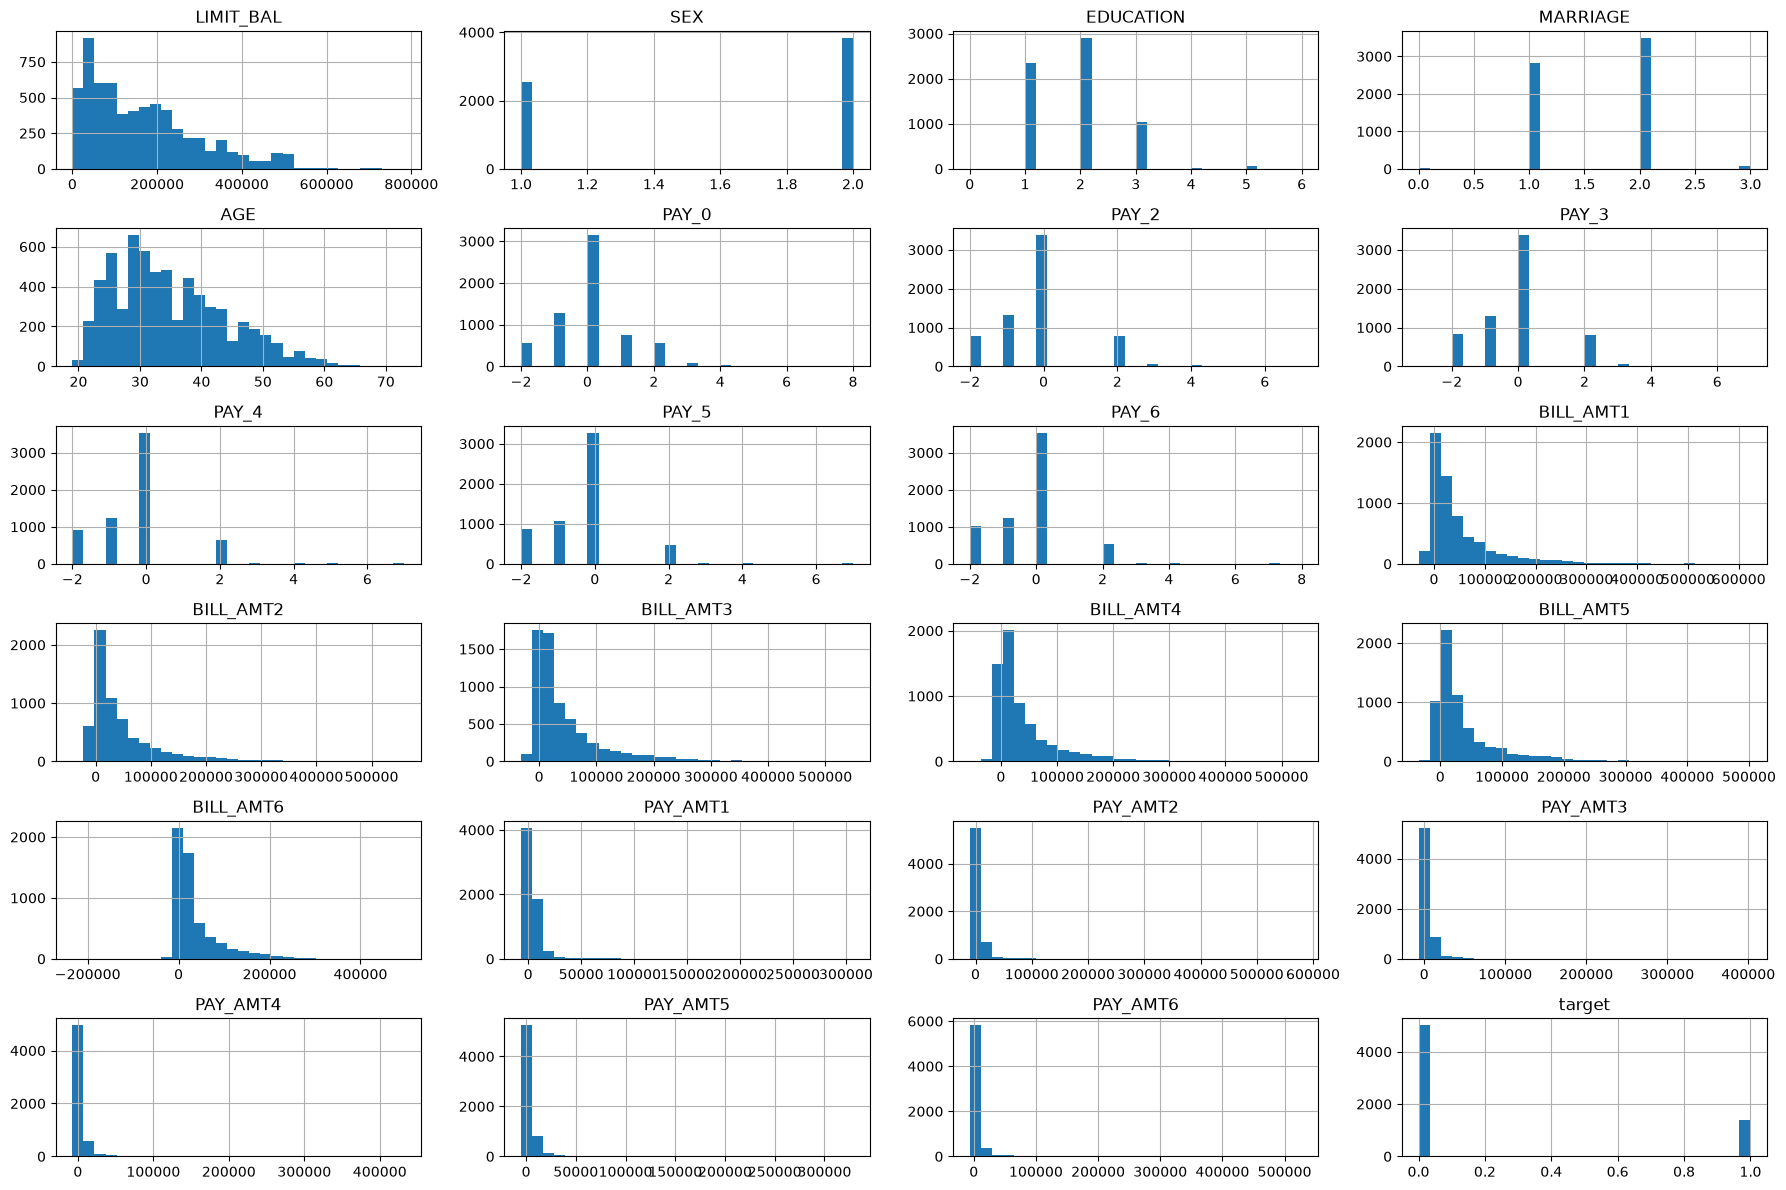

In [8]:
df.hist(bins=30, figsize=(18, 12), layout=(-1, 4))
plt.tight_layout()
plt.show()

Histogramy potwierdzają prawoskośność kwot, czyli większość klientów ma niższe rachunki i wpłaty, a nieliczni bardzo wysokie (długi prawy ogon). Zmienna `AGE` jest umiarkowanie prawoskośna i większość klientów w wieku 25–40 lat, a zmienne `PAY_*` skupiają się w wartościach -2, -1 i 0 (prawdopodobnie większość ludzi jest niezadłużonych).

In [9]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df[col].value_counts().sort_index())

SEX
1    2555
2    3845
Name: count, dtype: int64
EDUCATION
0       4
1    2352
2    2910
3    1030
4      29
5      69
6       6
Name: count, dtype: int64
MARRIAGE
0      11
1    2824
2    3501
3      64
Name: count, dtype: int64


Przeważają w dużej mierze kobiety, osoby z wykształceniem wyższym (1, 2) oraz osoby w stanie wolnym i związku małżeńskim. Kategorie "inne" w `EDUCATION` (0, 4, 5, 6) i `MARRIAGE` (0, 3) są rzadkie.

In [10]:
pay_cols = [c for c in df.columns if c.startswith("PAY_") and 'AMT' not in c]

print("Procent klientów z PAY <= 0:")
print((df[pay_cols].apply(lambda s: (s.dropna() <= 0).mean()) * 100).round(1))

pay_counts = df[pay_cols].apply(lambda s: s.value_counts()).fillna(0).astype(int)
pay_counts.index = pay_counts.index.astype(int)
pay_counts


Procent klientów z PAY <= 0:
PAY_0    77.8
PAY_2    85.9
PAY_3    86.2
PAY_4    88.9
PAY_5    90.7
PAY_6    90.8
dtype: float64


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-3,0,0,1,0,0,0
-2,561,786,837,911,867,1031
-1,1270,1331,1302,1238,1080,1235
0,3148,3379,3378,3540,3279,3542
1,752,10,0,0,1,1
2,555,792,796,636,473,524
3,71,65,52,34,30,37
4,25,27,18,14,14,14
5,9,5,2,13,9,3
6,4,0,8,3,0,1


W każdym miesiącu 77-91% klientów ma status poniżej lub równy 0 (prawdopodobnie spłata, brak zadłużenia).

Dodatnie wartości to opóźnienia, możliwe, że liczba zaległych rat. Z tabeli widać, że:
* opóźnienia powyżej 2 są rzadkie,a wartości 5-8 jest bardzo mało,
* w miesiącu 0 (`PAY_0`) opóźnień jest najwięcej,
* Wartość `-3` występuje tylko raz w `PAY_3`, może to być jakiś rzadki status albo błąd,
* w `PAY_0` jest 752 jedynek, a w starszych miesiącach prawie wcale, za to dwójek dużo,

Interpretacja i tak jest jasna, im wyższa wartość, tym gorzej, więc traktuję `PAY_*` jako zmienne porządkowe.

### *1.2 Analiza wartości brakujących*
-------

In [11]:
df.isna().sum()

LIMIT_BAL      0
SEX            0
EDUCATION      0
MARRIAGE       0
AGE            0
PAY_0          0
PAY_2          0
PAY_3          0
PAY_4          0
PAY_5        636
PAY_6          0
BILL_AMT1      0
BILL_AMT2      0
BILL_AMT3      0
BILL_AMT4      0
BILL_AMT5      0
BILL_AMT6    653
PAY_AMT1       0
PAY_AMT2       0
PAY_AMT3       0
PAY_AMT4     635
PAY_AMT5       0
PAY_AMT6       0
target         0
dtype: int64

Braki występują tylko w `PAY_5`, `BILL_AMT6` i `PAY_AMT4`, w każdej jest to prawie 10% wszystkich obserwacji

Czy braki w kolumnach dotyczą tych samych wierszy?

In [12]:
na_cols = df.columns[df.isna().any()].tolist()
print('Kolumny z brakami:',na_cols)

na_in_row = df[na_cols].isna().sum(axis=1)
print("Wiersze z jakimkolwiek brakiem:", (na_in_row > 0).sum())
print(na_in_row.value_counts().sort_index()) 

Kolumny z brakami: ['PAY_5', 'BILL_AMT6', 'PAY_AMT4']
Wiersze z jakimkolwiek brakiem: 1743
0    4657
1    1569
2     167
3       7
Name: count, dtype: int64


Braki zwykle dotyczą pojedynczych kolumn (tylko 174 wiersze mają ponad 1 brak)

Czy braki niosą jakąś informację o targecie?


In [13]:
for col in na_cols:
    print(df.groupby(df[col].isna())['target'].mean().round(3))

PAY_5
False    0.214
True     0.230
Name: target, dtype: float64
BILL_AMT6
False    0.213
True     0.242
Name: target, dtype: float64
PAY_AMT4
False    0.215
True     0.224
Name: target, dtype: float64


Odsetki klasy 1 wśród wierszy z brakiem i bez są zbliżone, więc braki wyglądają na losowe.

Czy braki są w `X_test`?

In [14]:
X_test.isna().sum()[X_test.isna().sum() > 0]

PAY_5        164
BILL_AMT6    147
PAY_AMT4     165
dtype: int64

W `X_test` braki są w tych samych kolumnach


### *1.3 Wykrywanie wartości odstających*
-------

Boxploty dla zmiennych ciągłych

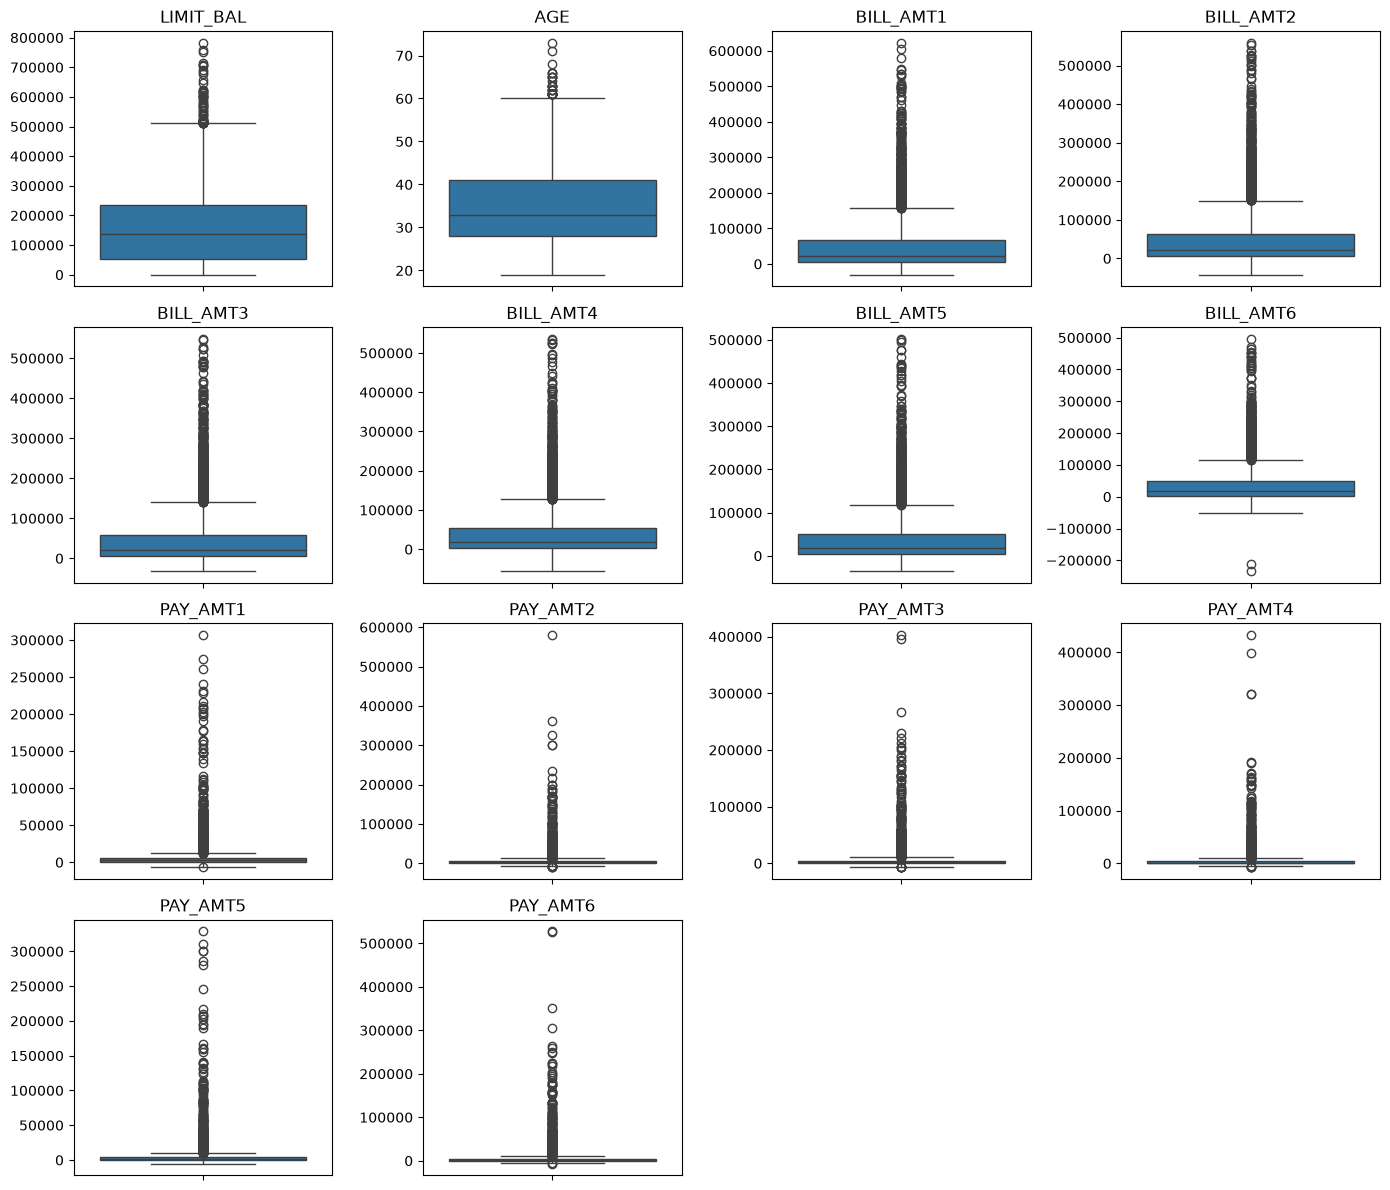

In [15]:
num_cols = ["LIMIT_BAL", "AGE"] + [c for c in df.columns if "AMT" in c]

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("")
for ax in axes[len(num_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Prawie wszystkie wartości odstające leżą w górnej części, to ten długi prawy ogon co w rozkładach (to nie są błędne wartości). `LIMIT_BAL` i `AGE` mają niewiele outlierów, natomiast pozostałe pudełka są bardzo wąskie w porównaniu z zakresem wartości. Rachunki sięgają 500/600 tys przy medianie w okolicach 20 tys, a wpłaty sięgają 300-600 tys przy medianie 2 tys.

In [16]:
def count_outliers(x):
    q1, q3 = x.quantile(0.25),x.quantile(0.75)
    iqr = q3-q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((x < lower)|(x > upper)).sum()

outliers = pd.DataFrame({
    "outliers_num": df[num_cols].apply(count_outliers),
    "outliers_%": (df[num_cols].apply(count_outliers)/len(df) * 100).round(2)
}).sort_values("outliers_num",ascending=False)

outliers

,outliers_num,outliers_%
PAY_AMT6,610,9.53
PAY_AMT5,603,9.42
BILL_AMT5,593,9.27
BILL_AMT4,590,9.22
PAY_AMT3,586,9.16
BILL_AMT3,575,8.98
PAY_AMT2,569,8.89
PAY_AMT1,563,8.80
BILL_AMT2,547,8.55
BILL_AMT6,541,8.45


Outliery IQR dotyczą głównie kwot (blisko 10%), powodem jest prawoskośność, nie błędy.


Policzę wartości niezgodne z opisem danych i podejrzane: ujemne kwoty, oraz kategorie "inne"

In [17]:
amt_cols = [c for c in df.columns if "AMT" in c] + ['LIMIT_BAL']
print((df[amt_cols] < 0).sum())

print("EDUCATION inne (0, 4, 5, 6):",df["EDUCATION"].isin([0,4,5,6]).sum())
print("MARRIAGE inne (0, 3):", df['MARRIAGE'].isin([0,3]).sum())

BILL_AMT1     833
BILL_AMT2     873
BILL_AMT3     903
BILL_AMT4     927
BILL_AMT5     936
BILL_AMT6     890
PAY_AMT1      920
PAY_AMT2     1132
PAY_AMT3     1085
PAY_AMT4     1093
PAY_AMT5     1155
PAY_AMT6     1219
LIMIT_BAL       1
dtype: int64
EDUCATION inne (0, 4, 5, 6): 108
MARRIAGE inne (0, 3): 75


* Ujemne `BILL_AMT` moze oznaczać nadpłatę, jest ich dużo, więc to nie powinny być błędy,
* Ujemne `PAY_AMT` ciężko mi zinterpretować, mogą oznaczać np. zwrot środków lub korektę. Ze względu na dużą liczbę nie traktuję ich jako błędów,
* Ujemny `LIMIT_BAL` to jedna obserwacja i nie ma sensu dla limitu kredytowego. To prawdopodobnie błąd w danych (poprawię to w KM2),
* Kategorie "inne" w `EDUCATION` i `MARRIAGE` są zgodne z opisem, ale dosyć rzadkie i rozbite na kilka kodów (w KM2 może połączę je w jedną kategorię).

### *1.4 Analiza relacji i istotności zmiennych*
-------

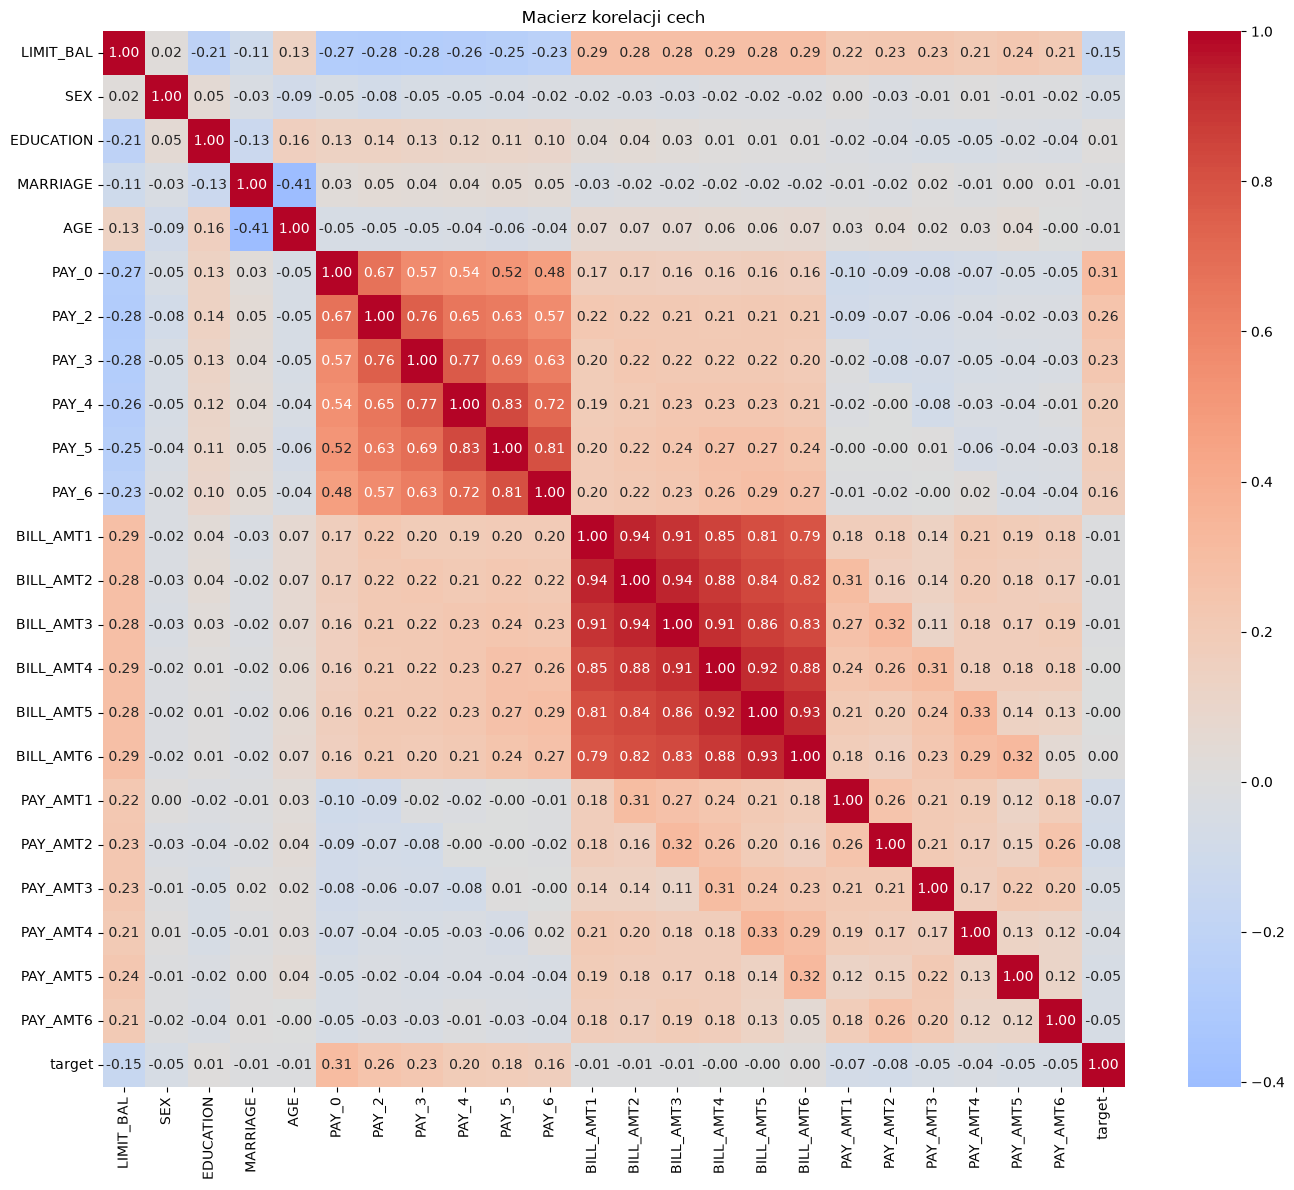

In [18]:
plt.figure(figsize=(14, 12))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, annot=True, fmt=".2f")
plt.title("Macierz korelacji cech")
plt.tight_layout()
plt.show()

Widać silnie skorelowane grupy cech: `BILL_AMT1–6` oraz `PAY_0–6` kolejne miesiące niosą bliską informację. Drzewu decyzyjnemu to nie przeszkadza, ale można to zapamiętać do KM2.

In [19]:
corr_target = df.corr()["target"].drop("target").sort_values(key=abs, ascending=False)
corr_target

PAY_0        0.310605
PAY_2        0.255786
PAY_3        0.225601
PAY_4        0.197105
PAY_5        0.184519
PAY_6        0.164642
LIMIT_BAL   -0.153207
PAY_AMT2    -0.078448
PAY_AMT1    -0.072768
PAY_AMT3    -0.054294
PAY_AMT6    -0.053606
PAY_AMT5    -0.053210
SEX         -0.047062
PAY_AMT4    -0.036942
EDUCATION    0.013650
BILL_AMT1   -0.012699
AGE         -0.011118
MARRIAGE    -0.010027
BILL_AMT3   -0.008144
BILL_AMT2   -0.007876
BILL_AMT5   -0.001776
BILL_AMT4   -0.001427
BILL_AMT6    0.000486
Name: target, dtype: float64

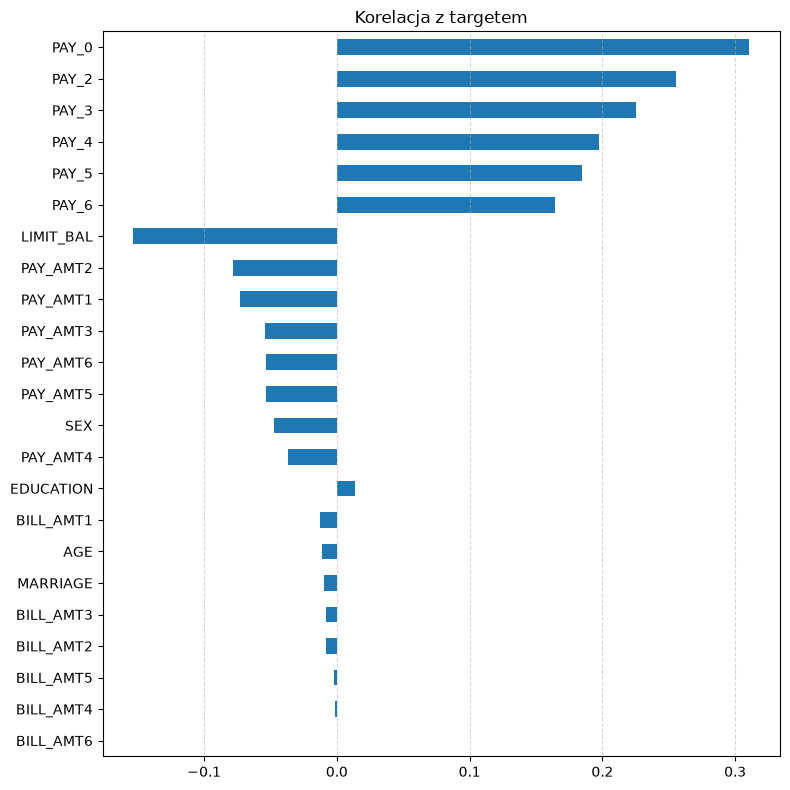

In [20]:
ax = corr_target.iloc[::-1].plot(kind="barh",figsize=(8,8),title="Korelacja z targetem")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

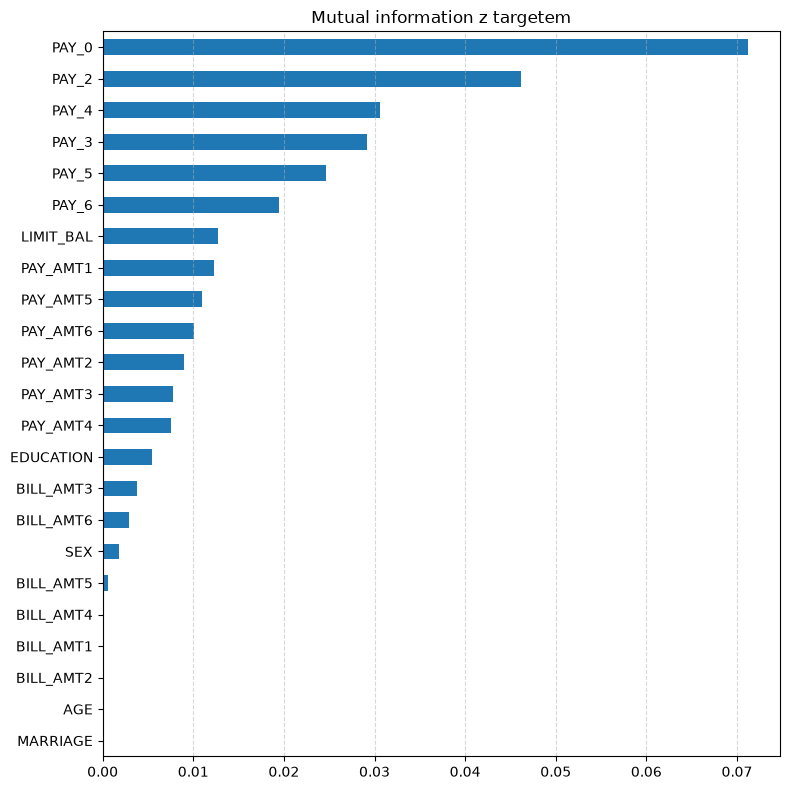

In [21]:
mic = mutual_info_classif(X_train.fillna(X_train.median()), df["target"], n_neighbors=10, random_state=67)
mic = pd.Series(mic, index=X_train.columns).sort_values()
ax = mic.plot(kind="barh",figsize=(8,8),title="Mutual information z targetem")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Korelacja Pearsona mierzy zależność liniową, dlatego policzyłem też mutual information, które potrafi wychwycić zależności nieliniowe. Potwierdza ono wnioski z korelacji: Najważniejsze są statusy spłat `PAY_*` oraz `LIMIT_BAL`, a kwoty rachunków `BILL_AMT*` mało niosą informacji o targecie. n_neighbors wybrałem 10, ponieważ sprawdzając dla różnych wartości (3,5,10,20,30) przy 10 wyniki się stabilizują.

Dla `PAY_0`, które ma największy wpływ na target, zrobię wykres odsetka klasy 1 targetu dla każdej wartości tej cechy

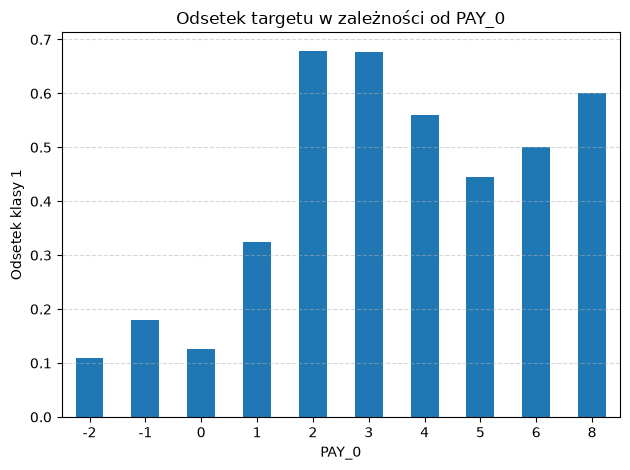

In [22]:
df.groupby("PAY_0")["target"].mean().plot(kind="bar", title="Odsetek targetu w zależności od PAY_0", rot=0)
plt.ylabel("Odsetek klasy 1")
plt.tight_layout()
plt.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.show()

Wyraźny skok ryzyka. Dla `PAY_0` mniejszego lub równego 0 (spłata w terminie) odsetek klasy 1 wynosi poniżej 0.2, dla `PAY_0` = 1, około 0.32, a dla 2+ ok. 0.4–0.7.

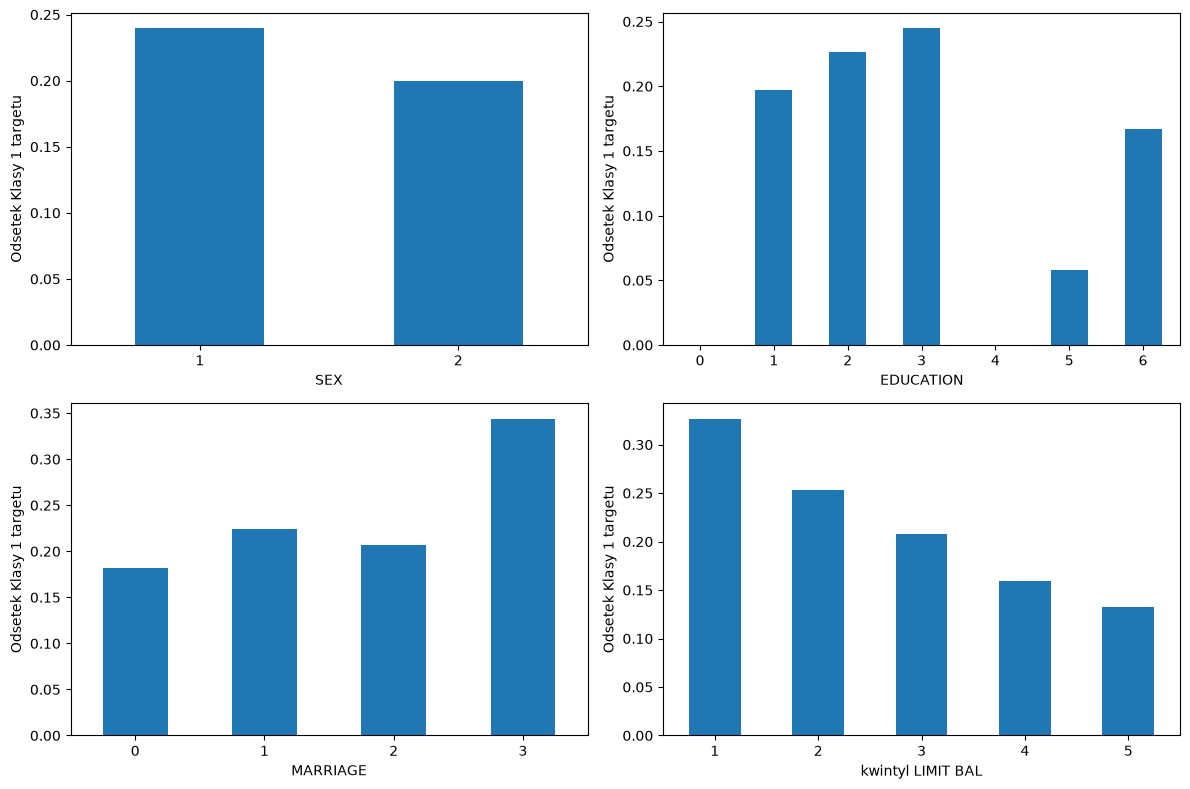

In [23]:
df["kwintyl LIMIT BAL"] = pd.qcut(df["LIMIT_BAL"], 5, labels=False) + 1

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(["SEX", "EDUCATION", "MARRIAGE", "kwintyl LIMIT BAL"]):
    df.groupby(col)["target"].mean().plot(kind="bar",ax=axes.flat[i], ylabel='Odsetek Klasy 1 targetu', rot=0)
    
plt.tight_layout()
plt.show()


Im wyższy limit kredytowy, tym mniejsze ryzyko klasy 1. Rzadkie kategorie z `EDUCATION` (0, 4, 5, 6) mają niższy  odsetek klasy 1 (ale są tak małe że to mało wiarygodne)


### *1.5 Wnioski z EDA*
-------

* Target jest niezbalansowany (78% do 22%),
* Najsilniejszy związek z targetem mają statusy spłat `PAY_*`. Widoczny jest też związek z `LIMIT_BAL`. Demografia i stan rachunków słabiej,
* W `EDUCATION` i `MARRIAGE` kategoria "inne" jest zakodowana kilkoma rzadkimi wartościami, można je do połączyć w pipeline KM2,
* Duże braki (około 10% na kolumnę) w `PAY_5`, `BILL_AMT6`, `PAY_AMT4`, są także w `X_test`. nie koncentrują się w tych samych wierszach i nie zależą wyraźnie od targetu,
* Zaszumienie danych: ujemne kwoty, jeden ujemny `LIMIT_BAL`, `PAY_3` = -3. Outliery IQR w kwotach to głównie naturalna prawoskośność rozkładów, drzewo jest na nie odporne.
* W ramach KM1 biorę wszystkie cechy, bez usuwania outlierów i bez imputacji. Drzewo decyzyjne wybiera cechy samo i jest odporne na wartości odstające, a `DecisionTreeClassifier` w sklearn obsługuje braki danych.

### *2. Metryka ewaluacji i podział danych*
-------

### *2.1 Metryka ewaluacji*
-------


Model końcowo ma zwracać wektor prawdopodobieństw przynależności do klasy 1, a nie samą etykietę 0/1. Wybiorę metrykę, która ocenia prawdopodobieństwa i nie zależy od progu odcięcia.

**Główna metryka: ROC AUC**
* ocenia, jak dobrze model porządkuje klientów według ryzyka. Sprawdza czy klienci, którzy się nie wywiązali, dostają wyższe prawdopodobieństwo niż pozostali,
* nie zależy od wyboru progu (w przeciwieństwie do precision, recall i F1),
* model losowy ma wartość 0.5, wynik łatwo zinterpretować.

**Metryka pomocnicza: Average Precision**
* skupia się na rzadszej klasie 1, czyli klientach w zwłoce,
* przy niezbalansowanych klasach jest surowsza niż ROC AUC.

Accuracy odpada, ponieważ klasy są niezbalansowane, więc model, który zawsze przewiduje 0, miałby accuracy około 0.78, a nie wykrywa żadnego klienta w zwłoce.

### *2.2 Podział danych*
-------



Strategia podziału:
* 80% zbiór treningowy. Na nim dobiorę hiperparametry za pomocą 5-krotnej stratyfikowanej walidacji krzyżowej,
* 20% – zbiór walidacyjny. użyję go raz, do końcowej oceny wybranego modelu.

Podział jest stratyfikowany, aby zachować proporcję klas 78% do 22%.


In [24]:
y = y_train["default.payment.next.month"]

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y, test_size=0.2,stratify=y, random_state=67
)

print("Treningowy:", X_tr.shape,", odsetek klasy 1:", round(y_tr.mean(), 3))
print("Walidacyjny:", X_val.shape,", odsetek klasy 1:", round(y_val.mean(), 3))


Treningowy: (5120, 23) , odsetek klasy 1: 0.216
Walidacyjny: (1280, 23) , odsetek klasy 1: 0.216


Przygotuję 5-krotną stratyfikowaną walidację krzyżową do doboru hiperparametrów

In [25]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=67)

### *3. Optymalizacja hiperparametrów drzewa decyzyjnego*
-------


Na początek drzewo z domyślnymi parametrami

In [26]:
base_tree = DecisionTreeClassifier(random_state=67).fit(X_tr, y_tr)

auc_tr = roc_auc_score(y_tr, base_tree.predict_proba(X_tr)[:, 1])
auc_cv = cross_val_score(DecisionTreeClassifier(random_state=67), X_tr, y_tr, cv=cv, scoring="roc_auc")

print("Głębokość:", base_tree.get_depth(), ", ilość liści:", base_tree.get_n_leaves())
print('AUC trening:', round(auc_tr,3))
print("AUC CV:", round(auc_cv.mean(),3), "+-", round(auc_cv.std(),3))

Głębokość: 34 , ilość liści: 709
AUC trening: 1.0
AUC CV: 0.6 +- 0.003


Drzewo pełne jest przeuczone, na treningu osiąga AUC = 1.0, a w walidacji krzyżowej tylko średnio 0.6. Drzewo zapamiętało dane treningowe zamiast nauczyć się zależności, trzeba ograniczyć jego złożoność odpowiednimi hiperparametrami.

### *3.1 Wybór hiperparametrów i przestrzeń poszukiwań*
-------
Zoptymalizuję hiperparametry:

* **max_depth**: bezpośrednio ograniczy złożoność modelu, aby drzewo nie było ani przeuczone, ani niedouczone. Sprawdzę zakres od 2 aż do braku limitu (34),
* **min_samples_leaf**: zapobiegnie tworzeniu liści dla małej liczby obserwacji, co dodatkowo da stabilniejsze prawdopodobieństwa (ważne dla AUC). Sprawdzę zakres od 1 do 500 (maksymalnie 8 liści dla około 4 tys obserwacji),
* **class_weight**: klasy są niezbalansowane, więc sprawdzę, czy nadanie większej wagi klasie 1 (balanced) pomaga. Nie dubluje działania dwóch pozostałych.

Zakresy obejmują drzewa zbyt proste, jak i zbyt złożone, więc optimum powinno leżeć wewnątrz siatki. 

Łącznie: 14 × 9 × 2 = 252 kombinacji

 Wartości w zakresach rosną nierównomiernie, bo wpływ parametru jest największy dla małych wartości.


In [27]:
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, 25, 30, None],
    "min_samples_leaf": [1, 5, 10, 20, 50, 100, 200, 300, 500],
    "class_weight": [None, "balanced"],
}

### *3.2 Osobny wpływ hiperparametrów*
-------
Najpierw sprawdzę wpływ max_depth i min_samples_leaf osobno. Porównam AUC na treningu i w walidacji krzyżowej.

max_depth: najlepsze AUC CV = 0.694 dla max_depth = 4
min_samples_leaf: najlepsze AUC CV = 0.731 dla min_samples_leaf = 300


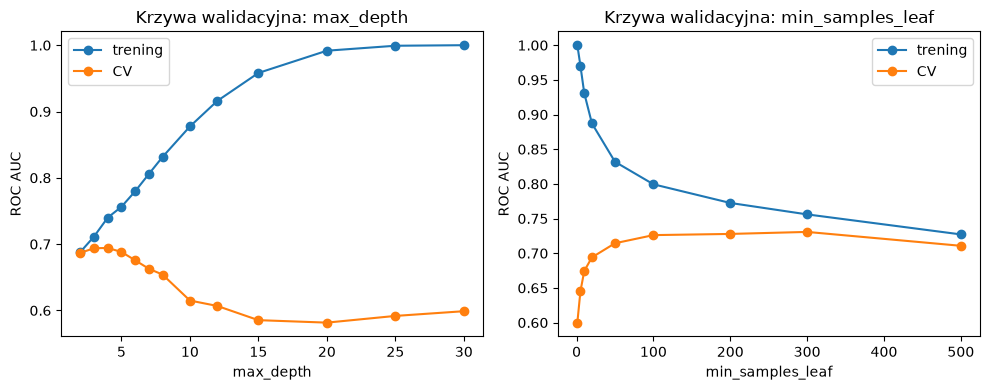

In [28]:
hp = ['max_depth','min_samples_leaf']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for i, par in enumerate(hp):
    values = [v for v in param_grid[par] if v is not None]
    train_scores, cv_scores = validation_curve(
        DecisionTreeClassifier(random_state=67), X_tr, y_tr,
        param_name=par, param_range=values, cv=cv, scoring="roc_auc"
    )
    cv_mean = cv_scores.mean(axis=1)
    best = np.argmax(cv_mean)
    print(f"{par}: najlepsze AUC CV = {cv_mean[best]:.3f} dla {par} = {values[best]}")
    axes[i].plot(values, train_scores.mean(axis=1), marker="o", label="trening")
    axes[i].plot(values, cv_mean, marker="o", label="CV")
    axes[i].set_xlabel(par)
    axes[i].set_ylabel("ROC AUC")
    axes[i].set_title(f"Krzywa walidacyjna: {par}")
    axes[i].legend()

plt.tight_layout()
plt.show()

* **max_depth**: AUC na treningu rośnie stale aż do 1 dla głębokości 30, a AUC w CV osiąga maksimum około 0.69 przy głębokości 4, a potem spada. Głębokie drzewo jest przeuczone,
* **min_samples_leaf**: im większe liście, tym mniejsze AUC na treningu, ale wyższe w CV, maksimum około 0.73 przy 300 obserwacjach w liściu.

### *3.3 Przeszukiwanie siatki hiperparametrów*
-------
Przeszukam teraz wszystkie kombinacje za pomocą GridSearchCV (z 5-krotną stratyfikowaną CV i metryką ROC AUC)

In [29]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=67),
    param_grid, scoring="roc_auc", cv=cv, n_jobs=-1
)
grid.fit(X_tr, y_tr)

print("Najlepsze parametry:", grid.best_params_)
print("Najlepsze AUC:", round(grid.best_score_, 3))

Najlepsze parametry: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 100}
Najlepsze AUC: 0.735


In [30]:
results = pd.DataFrame(grid.cv_results_)
results["param_class_weight"] = results["param_class_weight"].fillna("None")
print(results.groupby("param_class_weight")["mean_test_score"].max().round(4))

param_class_weight
None        0.7326
balanced    0.7353
Name: mean_test_score, dtype: float64


class_weight = Balanced działa minimalnie lepiej od None

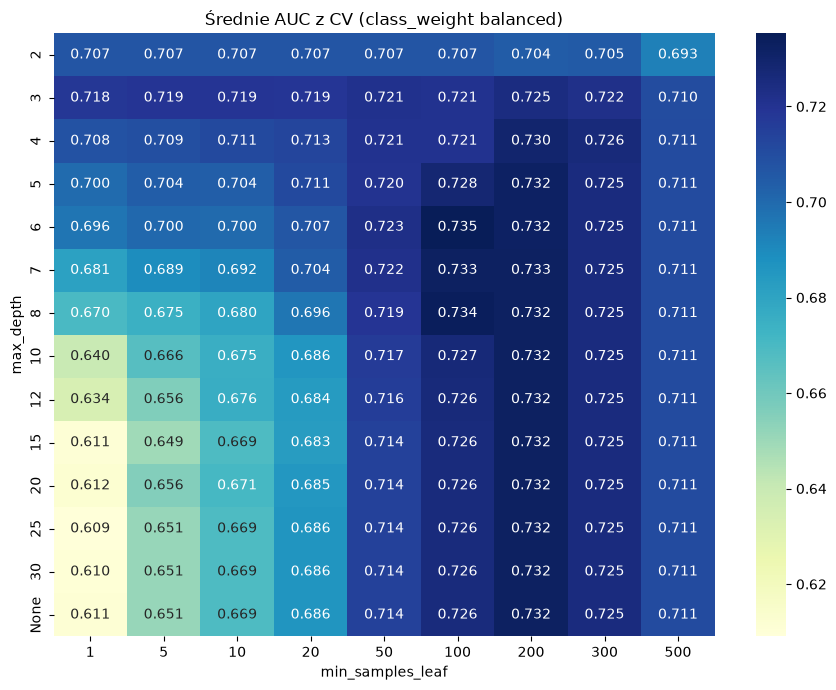

In [31]:
heat_map = results[results["param_class_weight"] == "balanced"].pivot_table(
    index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score", dropna=False)
heat_map = heat_map.rename(index=lambda x: 'None' if pd.isna(x) else int(x))

plt.figure(figsize=(9, 7))
sns.heatmap(heat_map, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title(f"Średnie AUC z CV (class_weight balanced)")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_depth")
plt.tight_layout()
plt.show()

* **class_weight** ma niewielki wpływ, najlepsze AUC dla balanced około 0.735, dla None 0.733,
* Najważniejsze jest **min_samples_leaf**. Przy małych liściach głębokie drzewa mocno się przeuczają, a przy liściach 100-300 i głębokości >= 3 wynik jest stabilny, niezależnie od głębokości,
* Przy **min_samples_leaf** = 100 zwiększanie **max_depth** powyżej 6 zmienia wynik minimalnie, duże liście same ograniczają rozrost drzewa,
* Optimum leży wewnątrz siatki dla obu parametrów, więc zakresy były dobrane poprawnie.

### *3.4 Wybór najlepszego modelu*
-------
Najlepsze kombinacje hiperparametrów według średniego AUC z CV:

In [32]:
cols = ["param_max_depth","param_min_samples_leaf","param_class_weight","mean_test_score","std_test_score","rank_test_score"]
results.sort_values("rank_test_score")[cols].head(10)

,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score,rank_test_score
167,6,100,balanced,0.735316,0.019591,1
185,8,100,balanced,0.733983,0.021138,2
176,7,100,balanced,0.732773,0.019608,3
177,7,200,balanced,0.732688,0.016847,4
43,6,300,None,0.732582,0.018461,5
204,12,200,balanced,0.732452,0.016712,6
222,20,200,balanced,0.732452,0.016712,6
186,8,200,balanced,0.732452,0.016712,6
195,10,200,balanced,0.732452,0.016712,6
249,None,200,balanced,0.732452,0.016712,6


In [33]:
best_params = grid.best_params_
best_tree = DecisionTreeClassifier(random_state=67, **best_params).fit(X_tr, y_tr)
print("Głębokość:", best_tree.get_depth(), ", ilość liści:", best_tree.get_n_leaves())

Głębokość: 6 , ilość liści: 20


Najlepsze kombinacje różnią się w AUC o ułamki tysięcznych, mniej niż odchylenie standardowe między foldami (około 0.017–0.021), więc różnice między nimi nie są istotne.

Wybieram model wskazany przez gridSearch: max_depth = 6, min_samples_leaf = 100, class_weight = balanced. Ma najwyższe AUC w CV, a przy tym jest małe - 20 liści, więc łatwo go zinterpretować.

### *3.5 Ocena wybranego modelu na zbiorze walidacyjnym*
-------

In [34]:
p_best = best_tree.predict_proba(X_val)[:, 1]
p_base = base_tree.predict_proba(X_val)[:, 1]

print("Wybrane drzewo, AUC na treningowym:", round(roc_auc_score(y_tr, best_tree.predict_proba(X_tr)[:, 1]), 3))
print("Wybrane drzewo, AUC:", round(roc_auc_score(y_val, p_best), 3), "; AP:", round(average_precision_score(y_val, p_best), 3))
print("Pełne drzewo, AUC:", round(roc_auc_score(y_val, p_base), 3), "; AP:", round(average_precision_score(y_val, p_base), 3))

Wybrane drzewo, AUC na treningowym: 0.771
Wybrane drzewo, AUC: 0.754 ; AP: 0.495
Pełne drzewo, AUC: 0.616 ; AP: 0.283


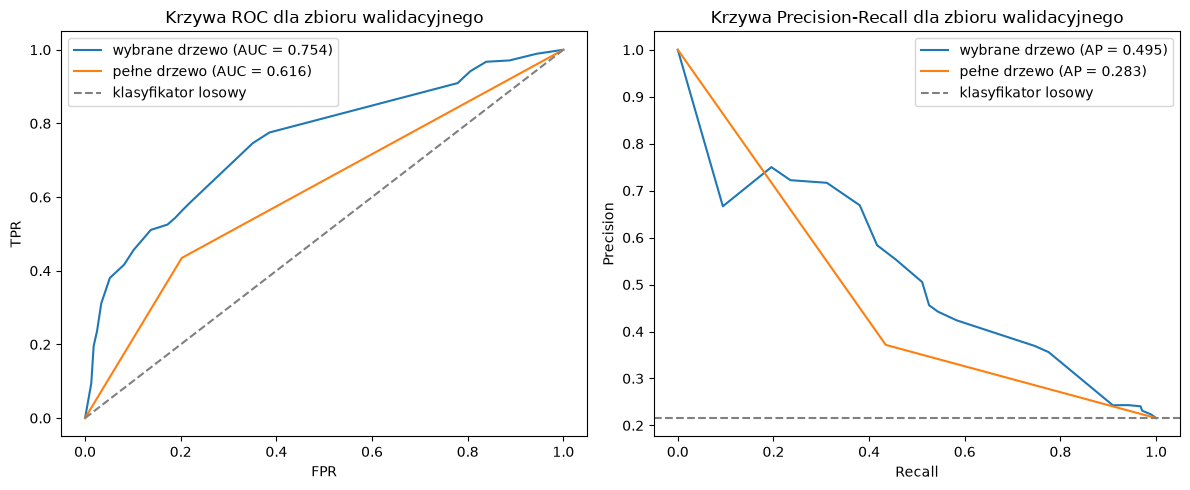

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for p,label in [(p_best, "wybrane drzewo"), (p_base, 'pełne drzewo')]:
    fpr, tpr, _ = roc_curve(y_val,p)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y_val, p):.3f})")
    precision, recall, _ = precision_recall_curve(y_val,p)
    axes[1].plot(recall, precision, label=f"{label} (AP = {average_precision_score(y_val, p):.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="klasyfikator losowy")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].set_title("Krzywa ROC dla zbioru walidacyjnego")
axes[0].legend()

axes[1].axhline(y_val.mean(), linestyle="--", color="gray", label="klasyfikator losowy")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Krzywa Precision-Recall dla zbioru walidacyjnego")
axes[1].legend()

plt.tight_layout()
plt.show()

* Wybrane drzewo osiąga na zbiorze walidacyjnym AUC 0.754, trochę więcej niż w CV (0.735) - różnica mieści się w rozrzucie między foldami w CV, więc model dobrze uogólnia,
* AP to w przybliżeniu 0.5,ponad dwukrotnie więcej niż klasyfikator losowy,
* Strojenie dało dużą poprawę względem pełnego drzewa: AUC wzrosło z 0.62 do 0.75, a AP z 0.28 do 0.50,
* AUC na treningu dla wybranego drzewa wynosi blisko 0.77, a więc różnica między treningiem a walidacją jest mała i model nie jest przeuczony.

### *3.6 Interpretacja modelu*
-------

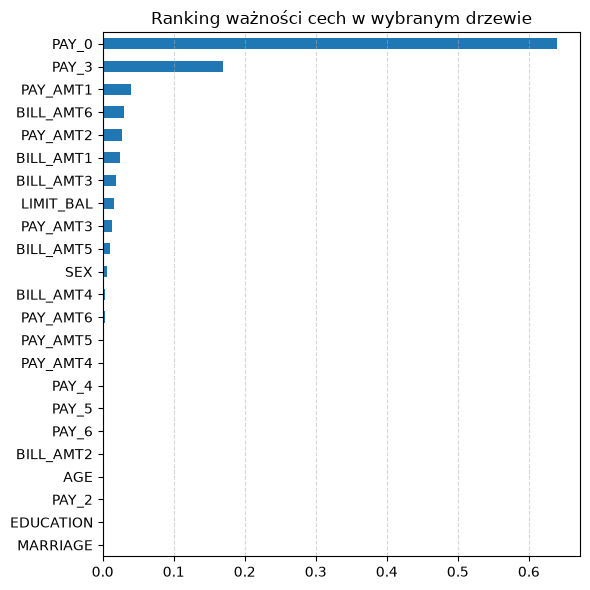

In [36]:
imp = pd.Series(best_tree.feature_importances_,index=X_tr.columns).sort_values()

ax = imp.plot(kind="barh", figsize=(6,6), title="Ranking ważności cech w wybranym drzewie")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

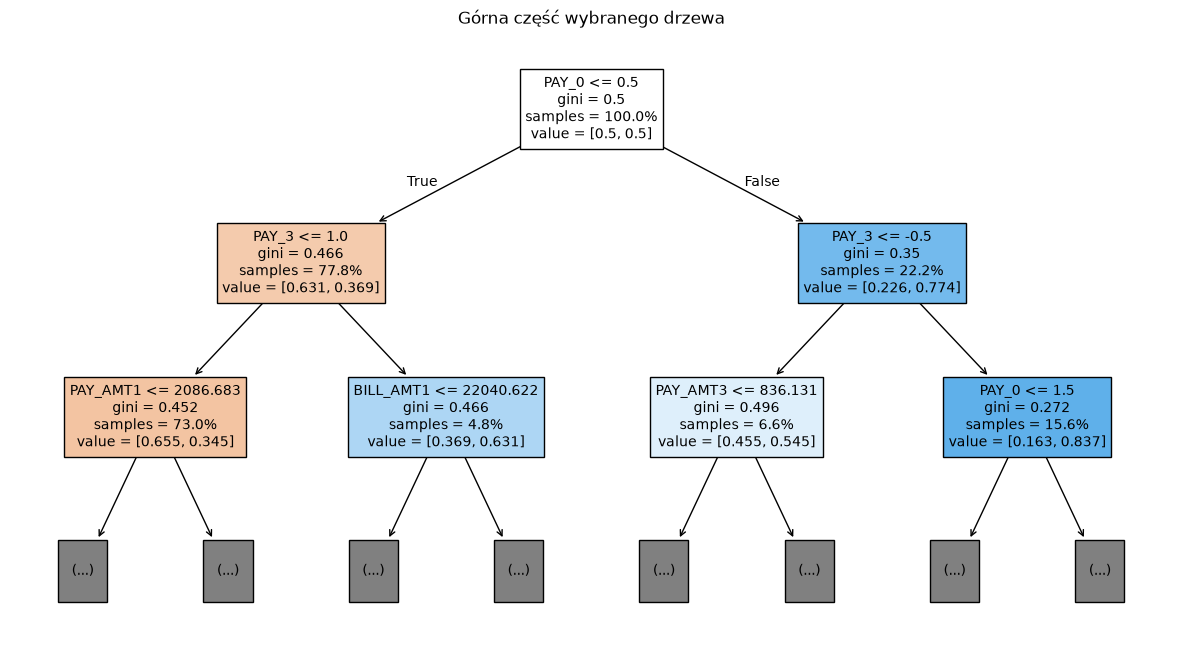

In [37]:
plt.figure(figsize=(15, 8))
plot_tree(best_tree, feature_names=X_tr.columns.tolist(), filled=True, max_depth=2, proportion=True, fontsize=10)
plt.title("Górna część wybranego drzewa")
plt.show()

* Drzewo opiera się przede wszystkim na `PAY_0` (ważność ponad 0.6) i `PAY_3` (około 0.17). Jest to zgodne z EDA, gdzie statusy spłat miały najsilniejszy związek z targetem,
* O dziwo `LIMIT_BAL` ma niski wpływ na model,
* Pozostałe cechy mają małą ważność (< 0.05),
* Pierwszy podział to `PAY_0` <= 0.5. Klienci z `PAY_0` >= 1 trafiają do gałęzi o wyższym odsetku klasy 1, co jest zgodne z EDA,
* Z powodu class_weight = balanced wartości na rysunku drzewa są ważone, więc proporcje w węzłach nie są surowymi odsetkami klasy 1.

### *4. Podsumowanie i wnioski*
-------

In [38]:
summary = pd.DataFrame({
    'AUC trening': [auc_tr, roc_auc_score(y_tr, best_tree.predict_proba(X_tr)[:, 1])],
    'AUC CV': [auc_cv.mean(), grid.best_score_],
    'AUC walidacja': [roc_auc_score(y_val, p_base), roc_auc_score(y_val, p_best)],
    'AP walidacja': [average_precision_score(y_val, p_base), average_precision_score(y_val, p_best)],
},index=["pełne drzewo","wybrane drzewo"]).round(3)
summary

,AUC trening,AUC CV,AUC walidacja,AP walidacja
pełne drzewo,1.000,0.600,0.616,0.283
wybrane drzewo,0.771,0.735,0.754,0.495


**Eksploracja danych**
* Klasy są niezbalansowane (78% do 22%), a dane zaszumione: ujemne kwoty, rzadkie kategorie "inne" w `EDUCATION` i `MARRIAGE` oraz ok. po 10% braków w `PAY_5`, `BILL_AMT6`, `PAY_AMT4` (również w `X_test`).
* Najsilniej z targetem związane są statusy spłat `PAY_*`, szczególnie `PAY_0`, oraz `LIMIT_BAL`,

**Metryka i podział danych**
- Jako główną metrykę wybrałem **ROC AUC**, ponieważ nie zależy od progu, ocenia prawdopodobieństwa, nie zależy od proporcji klas. Metryka pomocnicza to **AP**. Accuracy została odrzucona, ponieważ model wybierający zawsze 0 miałby accuracy 0.78.
- `X_train` podzieliłem w sposób stratyfikowany 80/20, hiperparametry dobrałem 5-krotną stratyfikowaną CV, a zbioru walidacyjnego użyłem raz.

**Optymalizacja drzewa decyzyjnego**
* Pełne drzewo jest silnie przeuczone (AUC = 1.0 na treningu, 0.60 w CV i 0.62 na walidacji),
* Przeszukałem 252 kombinacje max_depth, min_samples_leaf i class_weight. Najważniejszy okazał się min_samples_leaf, duże liście ograniczają przeuczenie; class_weight miał bardzo niski wpływ,
* Wybrany model otrzymał: **max_depth = 6, min_samples_leaf = 100, class_weight = balanced**, najlepsze hiperparametry według GridSearch, a przy tym mały (20 liści),
* Wynik na zbiorze walidacyjnym **AUC = 0.754** jest zgodny z CV (0.735), więc model dobrze uogólnia. Strojenie poprawiło AUC o 0.14 względem pełnego drzewa,

**Pomysły na kamień milowy 2**
- Pipeline: imputacja braków, połączenie rzadkich kategorii `EDUCATION` i `MARRIAGE`, obsługa wartości niezgodnych z opisem danych.